In [92]:
import joblib
import io
import boto3
import sys
import polars as pl
import pandas as pd
import polars.selectors as cs
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import defaultdict
from botocore import UNSIGNED
from botocore.config import Config

sys.path.insert(0, "/home/onyxia/work/electera/src")

from electera.components.data_processing.data_loader import DataLoader

In [93]:
DATA_PATH = "s3://arthurmanceau/election_modeling_uhcp/data/"
SOURCE = "derived/processed/data_processed_presidentiel_legislative_from1950_to2027_20261006_185710.parquet/"

In [94]:
def load_election_results(year, election_type, political_trends):
        election_type_long = 'presidentiel' if election_type == 'pres' else 'legislative'
        ground_truth_data_path = (
            DATA_PATH
            + f"raw/elections/{election_type_long}/{year}/{election_type}{year}_csv/{election_type}{year}comm.parquet"
        )
        if "CGCCD" in political_trends or "tauCGCCD" in political_trends:
            political_trends_ = ["par", "CG", "C", "G", "D", "CD"]
            X_true = pl.read_parquet(
                ground_truth_data_path,
                storage_options={"aws_skip_signature": "true"},
            ).to_pandas()[
                ["codecommune", "nomcommune", "inscrits", "votants", "exprimes"]
                + [
                    f"vote{t.replace('tau', '')}"
                    for t in political_trends_
                    if t.replace("tau", "") != "par"
                ]
                + [
                    f"pvote{t.replace('tau', '')}"
                    for t in political_trends_
                    if t.replace("tau", "") != "par"
                ]
                + ["ppar"]
            ]
            X_true = X_true.copy()
            X_true["voteCGCCD"] = X_true["voteCG"] + X_true["voteC"] + X_true["voteCD"]
            X_true["pvoteCGCCD"] = (
                X_true["pvoteCG"] + X_true["pvoteC"] + X_true["pvoteCD"]
            )
        else:
            X_true = pl.read_parquet(
                ground_truth_data_path,
                storage_options={"aws_skip_signature": "true"},
            ).to_pandas()[
                ["codecommune", "nomcommune", "inscrits", "votants", "exprimes"]
                + [
                    f"vote{t.replace('tau', '')}"
                    for t in political_trends
                    if t.replace("tau", "") != "par"
                ]
                + [
                    f"pvote{t.replace('tau', '')}"
                    for t in political_trends
                    if t.replace("tau", "") != "par"
                ]
                + ["ppar"]
            ]
        X_true = X_true.dropna()
        str_cols = ["codecommune", "nomcommune"]
        float_cols = [
            f"pvote{t.replace('tau', '')}"
            for t in political_trends
            if t.replace("tau", "") != "par"
        ] + ["ppar"]
        int_cols = [
            f"vote{t.replace('tau', '')}"
            for t in political_trends
            if t.replace("tau", "") != "par"
        ] + ["inscrits", "votants", "exprimes"]
        X_true[str_cols] = X_true[str_cols].astype(str)
        X_true[int_cols] = X_true[int_cols].astype(int)
        X_true[float_cols] = X_true[float_cols].astype(float)
        exprimes_ = X_true[
            [
                f"vote{t.replace('tau', '')}"
                for t in political_trends
                if t.replace("tau", "") != "par"
            ]
        ].sum(axis=1)

        X_true = X_true.loc[
            ~(
                X_true["codecommune"].isin(
                    ["75056"]
                    + [f"1320{i}" for i in range(1, 9 + 1)]
                    + [f"132{i}" for i in range(10, 16 + 1)]
                    + [f"69328{i}" for i in range(1, 9 + 1)]
                )
            ),
            :,
        ]
        return X_true

In [95]:
def load_dataset(year, election_type):
    return  pl.scan_parquet(
                DATA_PATH + SOURCE,
                storage_options={"aws_skip_signature": "true"},
            ).filter(pl.col('annee')==year).filter(pl.col('election_type')==election_type).collect().to_pandas()

In [96]:
def load_model(year, election_type, trends, version='6.0.0'):
    s3 = boto3.client(
        "s3",
        endpoint_url="https://minio.lab.sspcloud.fr",
        region_name="us-east-1",
        config=Config(signature_version=UNSIGNED),
    )

    bucket = "arthurmanceau"
    key = f"election_modeling_uhcp/data/output/models/model_{year}_{election_type}_{trends}_{version}.joblib"

    response = s3.get_object(Bucket=bucket, Key=key)
    return joblib.load(io.BytesIO(response["Body"].read()))

In [101]:
presidential_election_list = [1969, 2022, 1995, 1974, 1981, 1988, 2002, 2007, 2012, 2017]
legistlative_election_list = [2022, 1973, 1978, 1981, 1986, 1988, 1993, 1997, 2002, 2007, 2012, 2017, 2024]
presidential_election_list.sort()
legistlative_election_list.sort()
print(presidential_election_list)
print(legistlative_election_list)

[1969, 1974, 1981, 1988, 1995, 2002, 2007, 2012, 2017, 2022]
[1973, 1978, 1981, 1986, 1988, 1993, 1997, 2002, 2007, 2012, 2017, 2022, 2024]


In [102]:
# metrics[metric][trend][(model_year, eval_year)] = value
def nested():
    # election_type -> trends_key -> trend -> {(model_year, eval_year): value}
    return defaultdict(lambda: defaultdict(lambda: defaultdict(dict)))

election_lists = {'pres':presidential_election_list, 'leg': legistlative_election_list}
metrics = {"mae": nested(), "mse": nested()}

for election_type in ['leg', 'pres']:
    print(election_type)
    for political_trends in [["taupar", "tauDCD", "tauGCG", "tauC"], ["taupar", "tauTD", "tauTG"], ["taupar", "tauD", "tauG", "tauCGCCD"], ["taupar", "tauD", "tauG", "tauCD", "tauC", "tauCG"]]:
        print(political_trends)
        election_list = election_lists[election_type]
        for index in range(len(election_list)-1):
            # First iteration / Last iteration
            # index = 0 / 9
            # year_0 = 1969 (training data) / 2022 (training data)
            year_0 = election_list[index]
            print(year_0)
            trends = political_trends.copy()
            trends.sort()
            # Model corresponding is index+1 : 1974 / 2027
            model_0 = load_model(election_list[index+1], election_type=election_type, trends="_".join(map(str, trends)))
            # Iterate over next years, from index to the end
            for next_year in election_list[index:]:
                print(next_year)
                results = load_election_results(next_year, election_type=election_type, political_trends=political_trends)
                election_type_long = 'presidentiel' if election_type=='pres' else 'legislative'
                input_data = load_dataset(next_year, election_type=election_type_long)
                preds = model_0.predict_votes(input_data)
                X_merged = model_0.evaluate_predictions(preds, results)
                diff_cols = [
                    col for col in X_merged.columns if ("_diff" in col) and ("p" in col)
                ]
                # Mean absolute error (the original took the mean of signed diffs)
                mae_per_trend = X_merged[diff_cols].abs().mean(axis=0)
                rmse_per_trend = X_merged[diff_cols].pow(2).mean(axis=0).pow(0.5)

                for col in diff_cols:
                    trend = col.replace("_diff", "")
                    metrics["mae"][election_type]["_".join(political_trends)][trend][(year_0, next_year)] = mae_per_trend[col]
                    metrics["mse"][election_type]["_".join(political_trends)][trend][(year_0, next_year)] = rmse_per_trend[col]

leg
['taupar', 'tauDCD', 'tauGCG', 'tauC']
1973
1973
F_raw_agesexcommunes/prop4059
F_raw_agesexcommunes/prop4059
F_raw_agesexcommunes/prop4059
F_raw_agesexcommunes/prop4059


2026-10-13 16:58:22.477 | SUCCESS  | electera.components.modelling.election_predictor:evaluate_predictions:456 - Evaluation completed! Mean error is 3.80%


1978
F_raw_agesexcommunes/prop4059
F_raw_agesexcommunes/prop4059
F_raw_agesexcommunes/prop4059
F_raw_agesexcommunes/prop4059


2026-10-13 16:58:25.980 | SUCCESS  | electera.components.modelling.election_predictor:evaluate_predictions:456 - Evaluation completed! Mean error is 5.01%


1981
F_raw_agesexcommunes/prop4059
F_raw_agesexcommunes/prop4059
F_raw_agesexcommunes/prop4059
F_raw_agesexcommunes/prop4059


...

2026-10-13 17:39:34.618 | SUCCESS  | electera.components.modelling.election_predictor:evaluate_predictions:456 - Evaluation completed! Mean error is 16.41%


2017
2017
F_raw_cspcommunes/pcapi
F_raw_cspcommunes/pcapi
F_raw_cspcommunes/pcapi
F_pct_change_proprietairescommunes/ppropri
F_pct_change_proprietairescommunes/ppropri
F_raw_capitalimmobiliercommunes/capitalratio


2026-10-13 17:39:45.741 | SUCCESS  | electera.components.modelling.election_predictor:evaluate_predictions:456 - Evaluation completed! Mean error is 3.34%


2022
F_raw_cspcommunes/pcapi
F_raw_cspcommunes/pcapi
F_raw_cspcommunes/pcapi
F_pct_change_proprietairescommunes/ppropri
F_pct_change_proprietairescommunes/ppropri
F_raw_capitalimmobiliercommunes/capitalratio


2026-10-13 17:39:50.212 | SUCCESS  | electera.components.modelling.election_predictor:evaluate_predictions:456 - Evaluation completed! Mean error is 9.17%


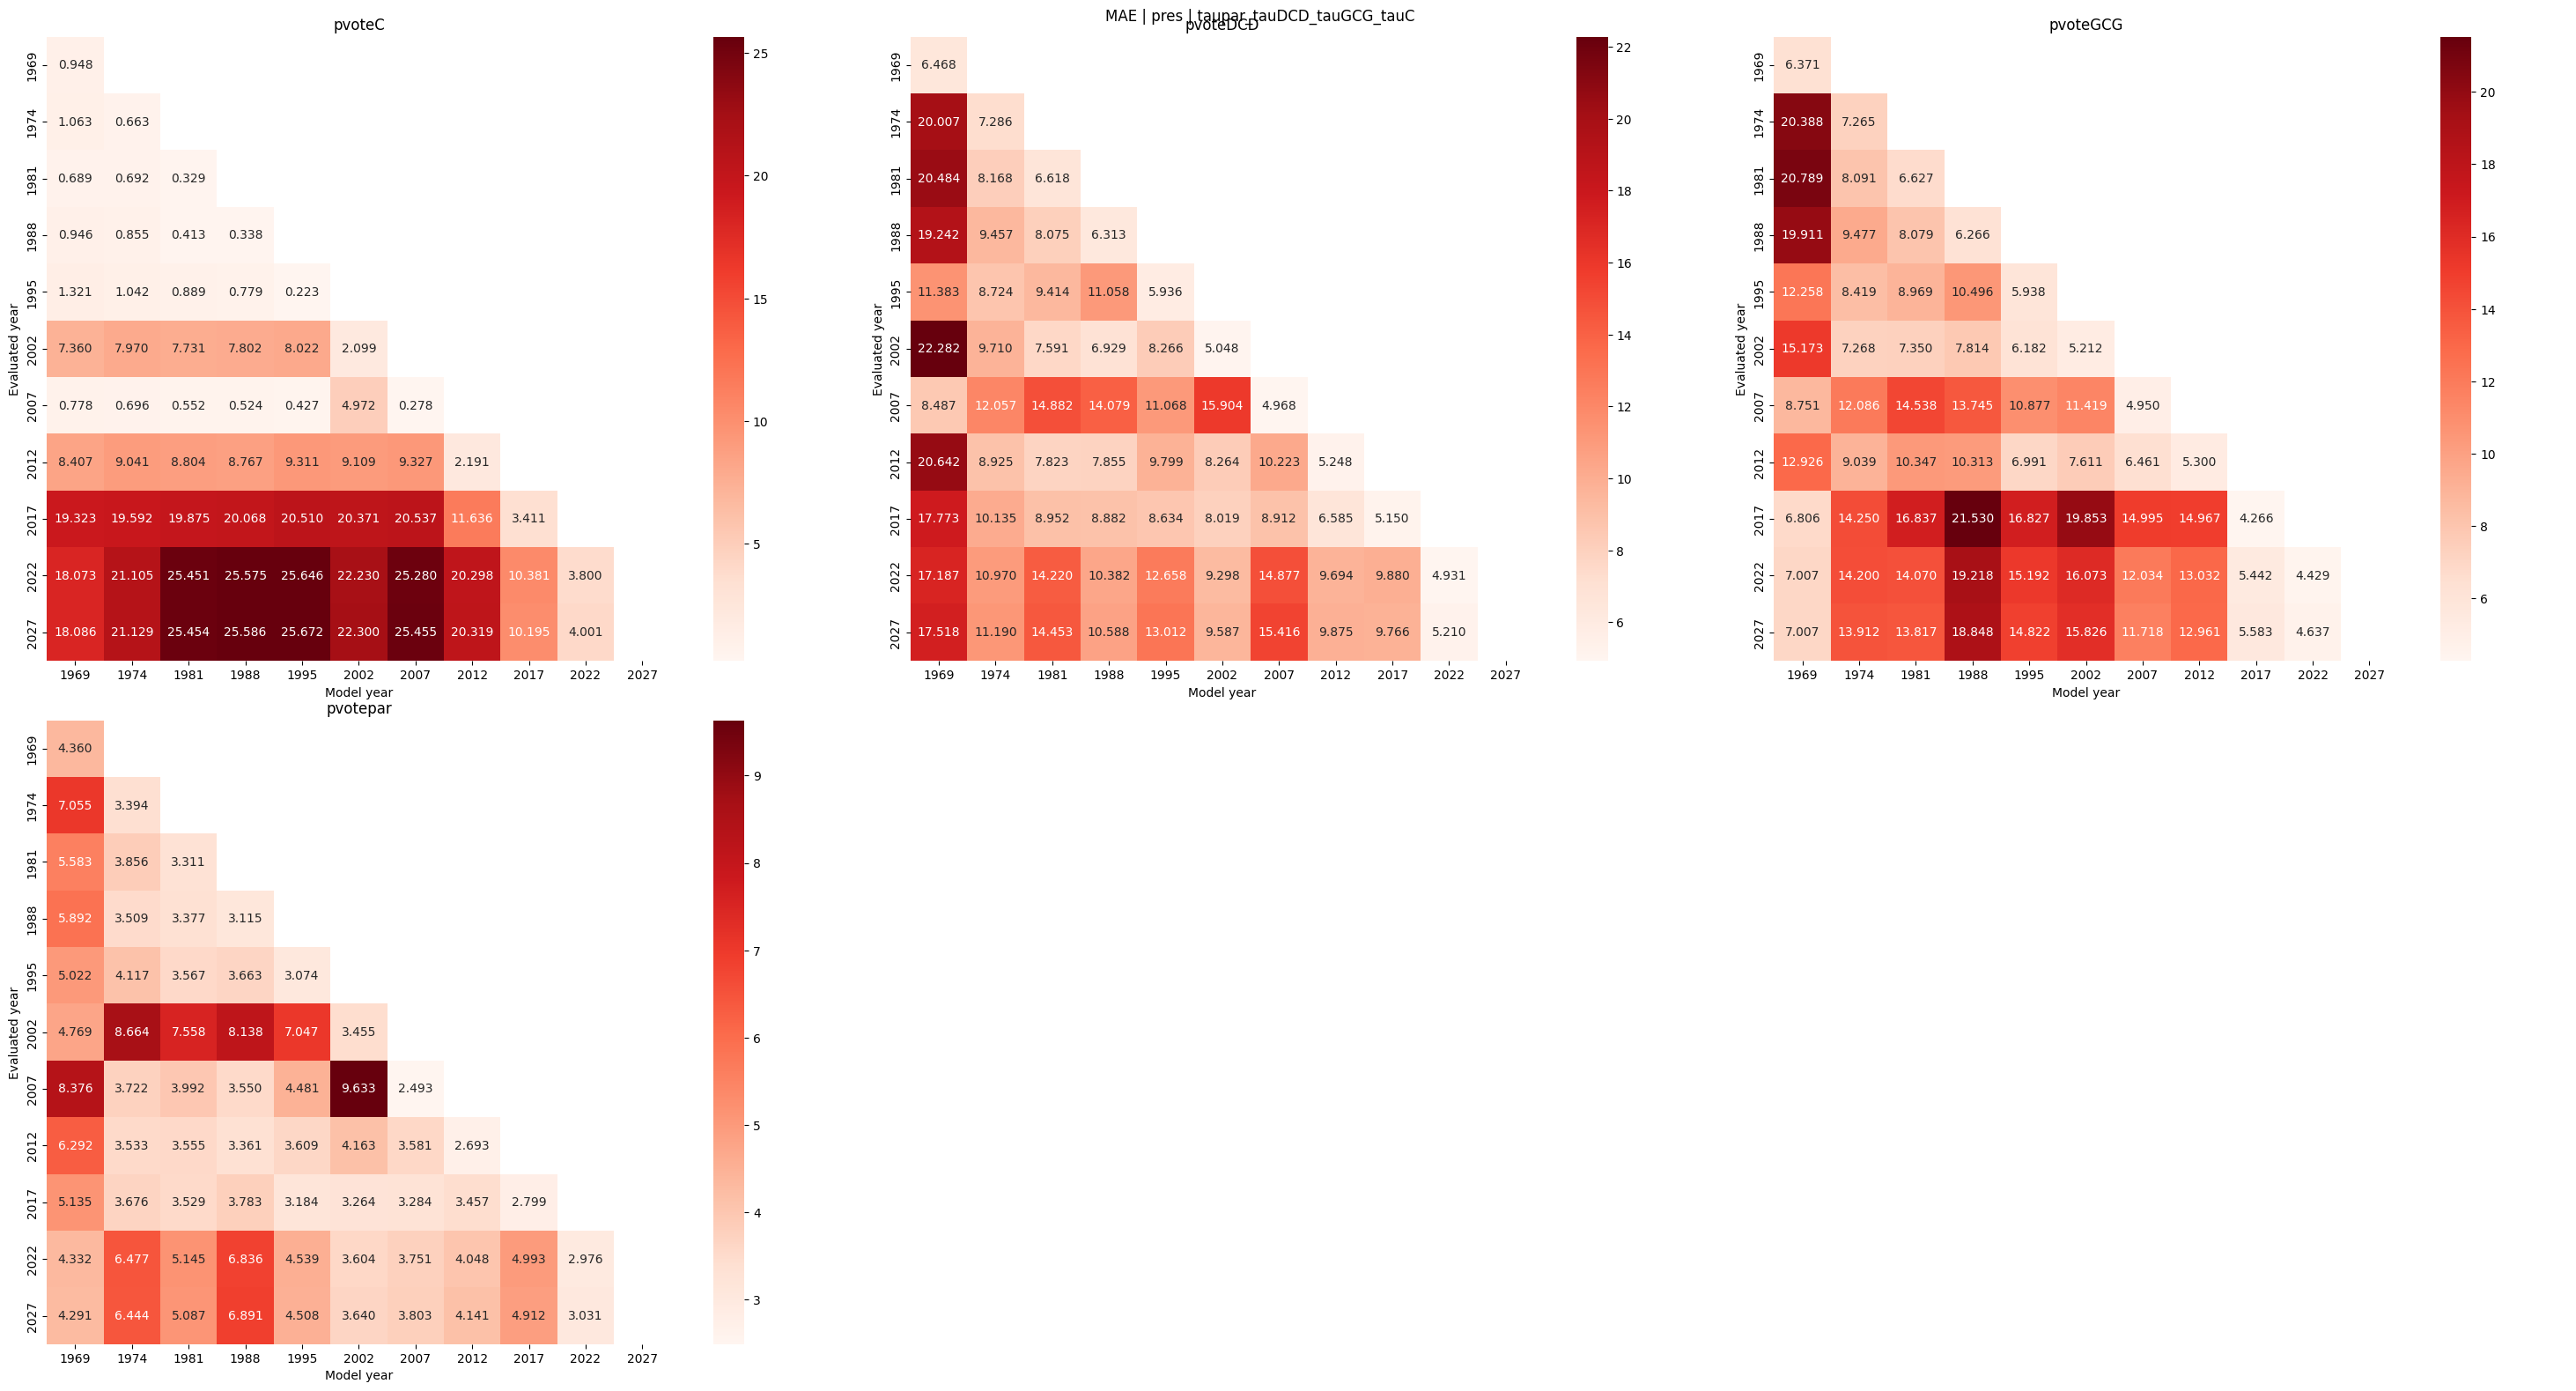

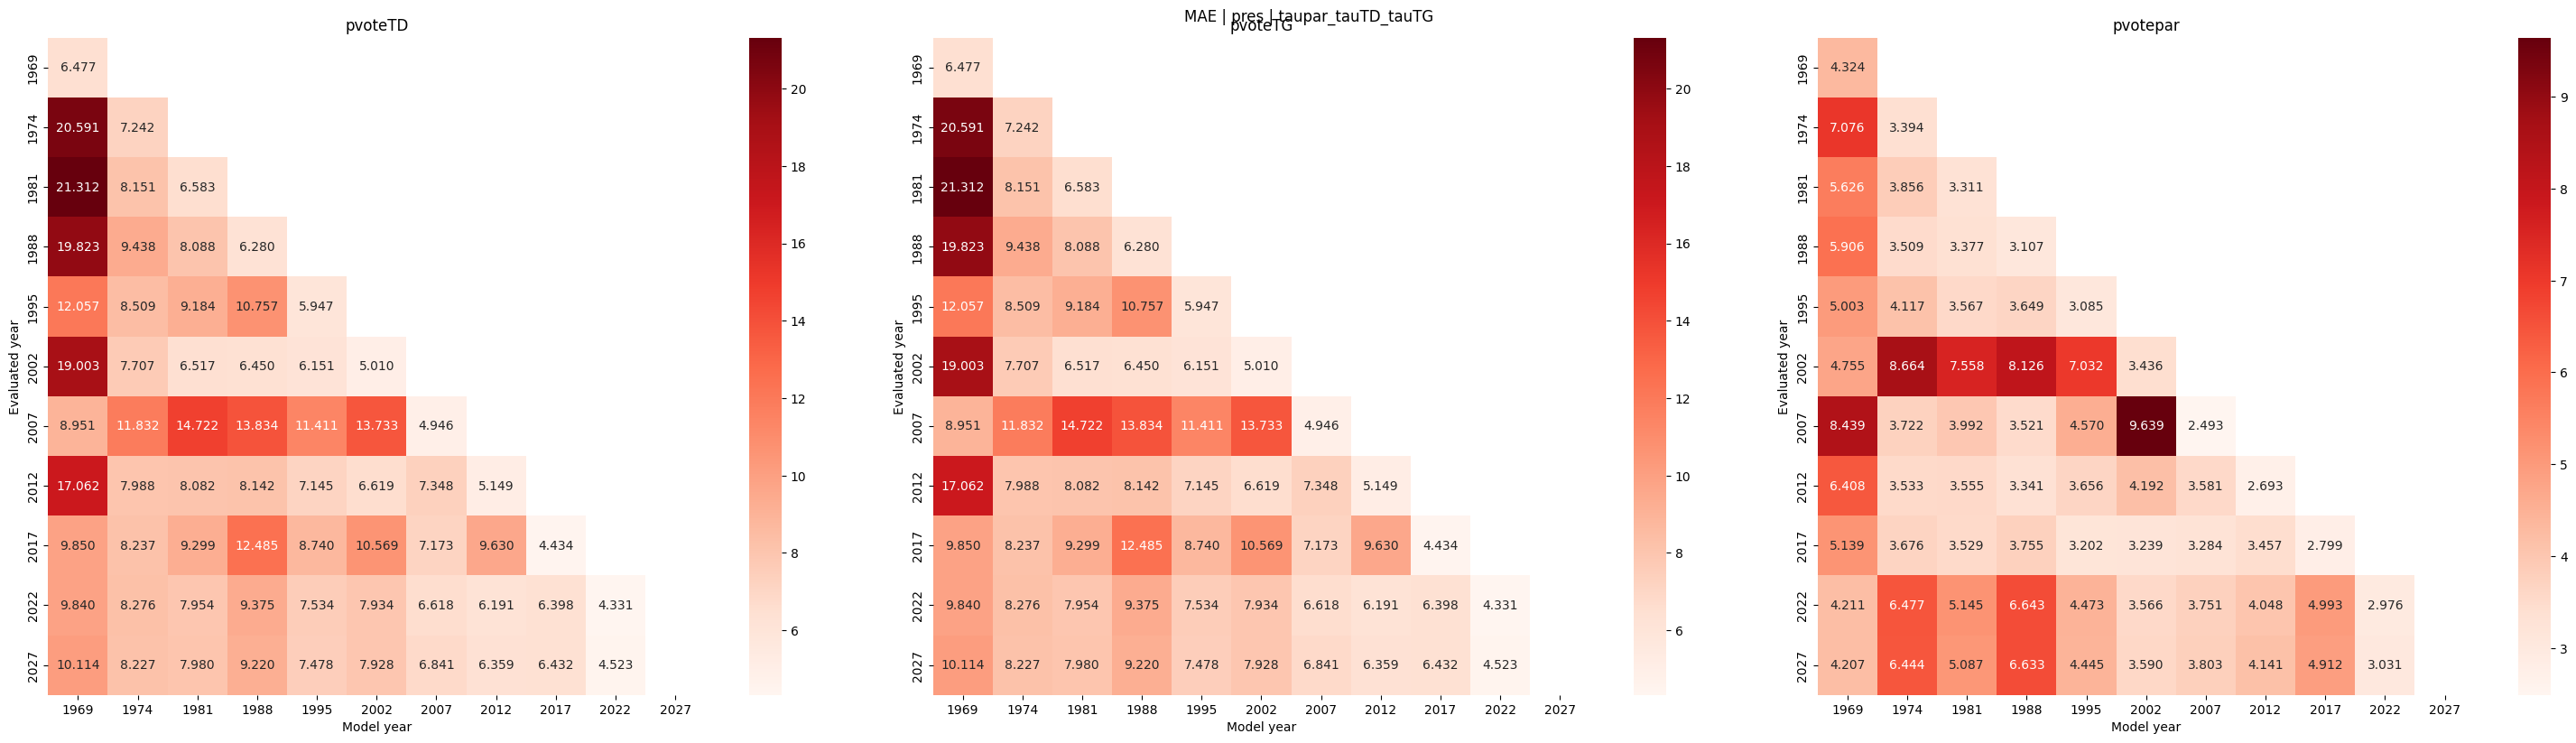

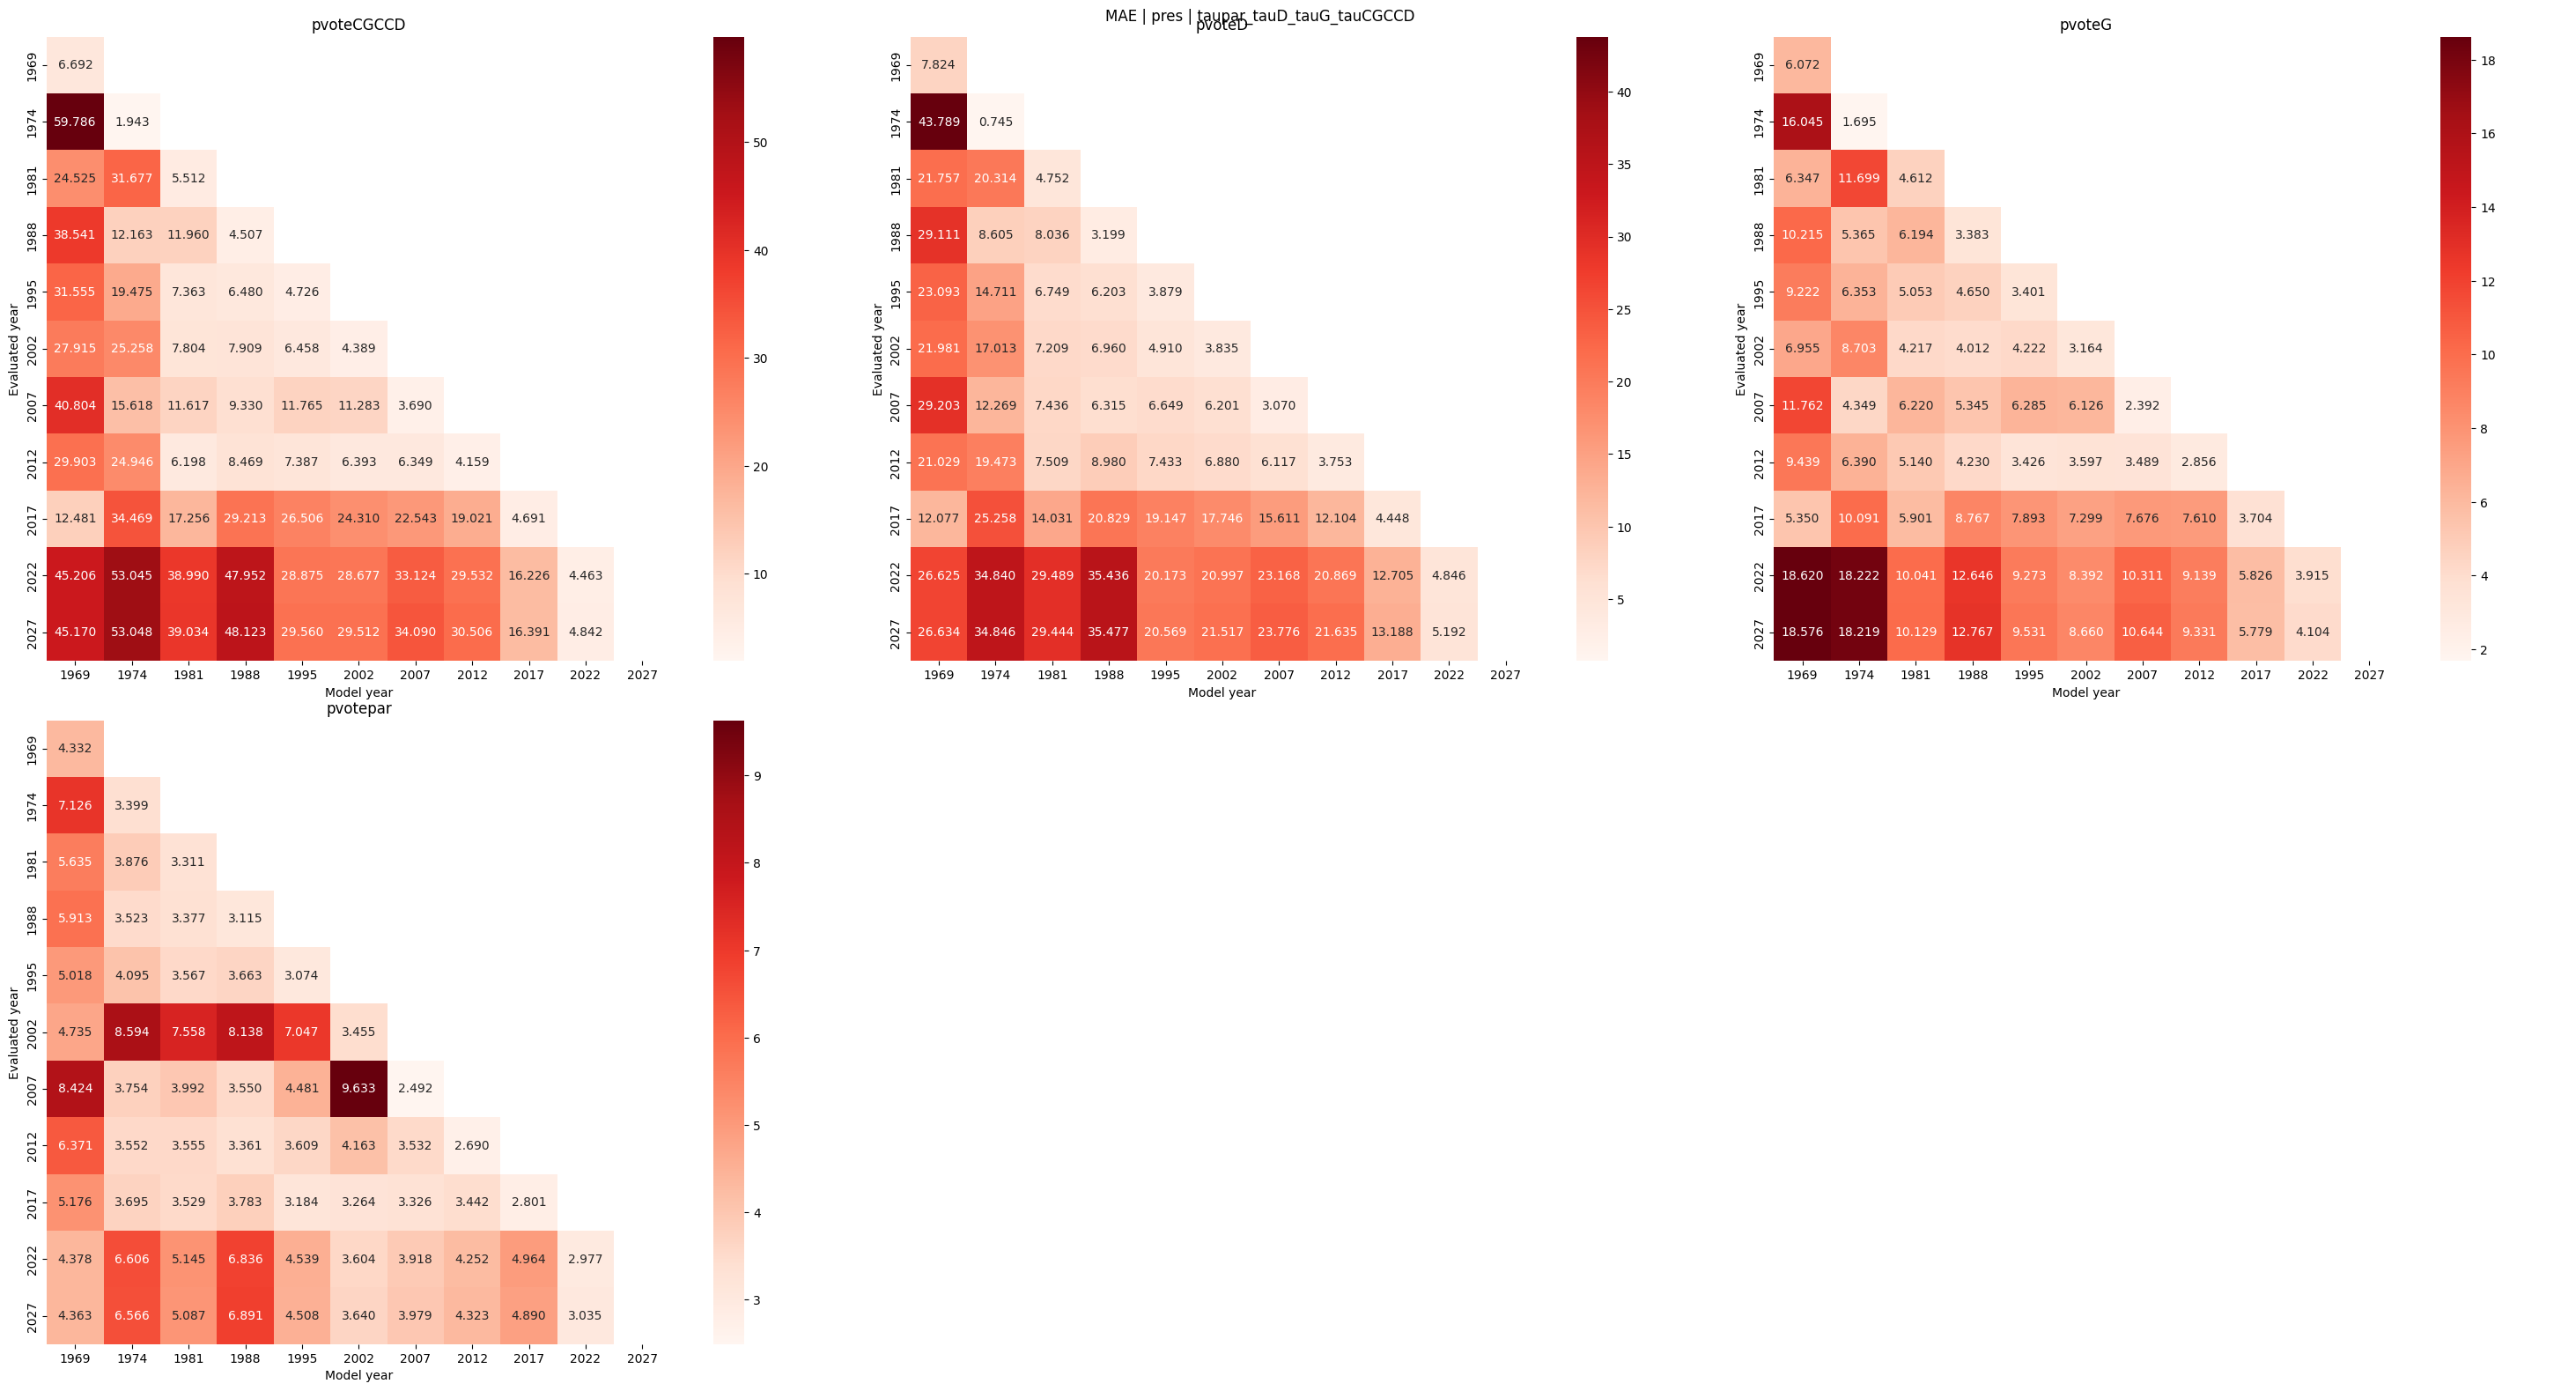

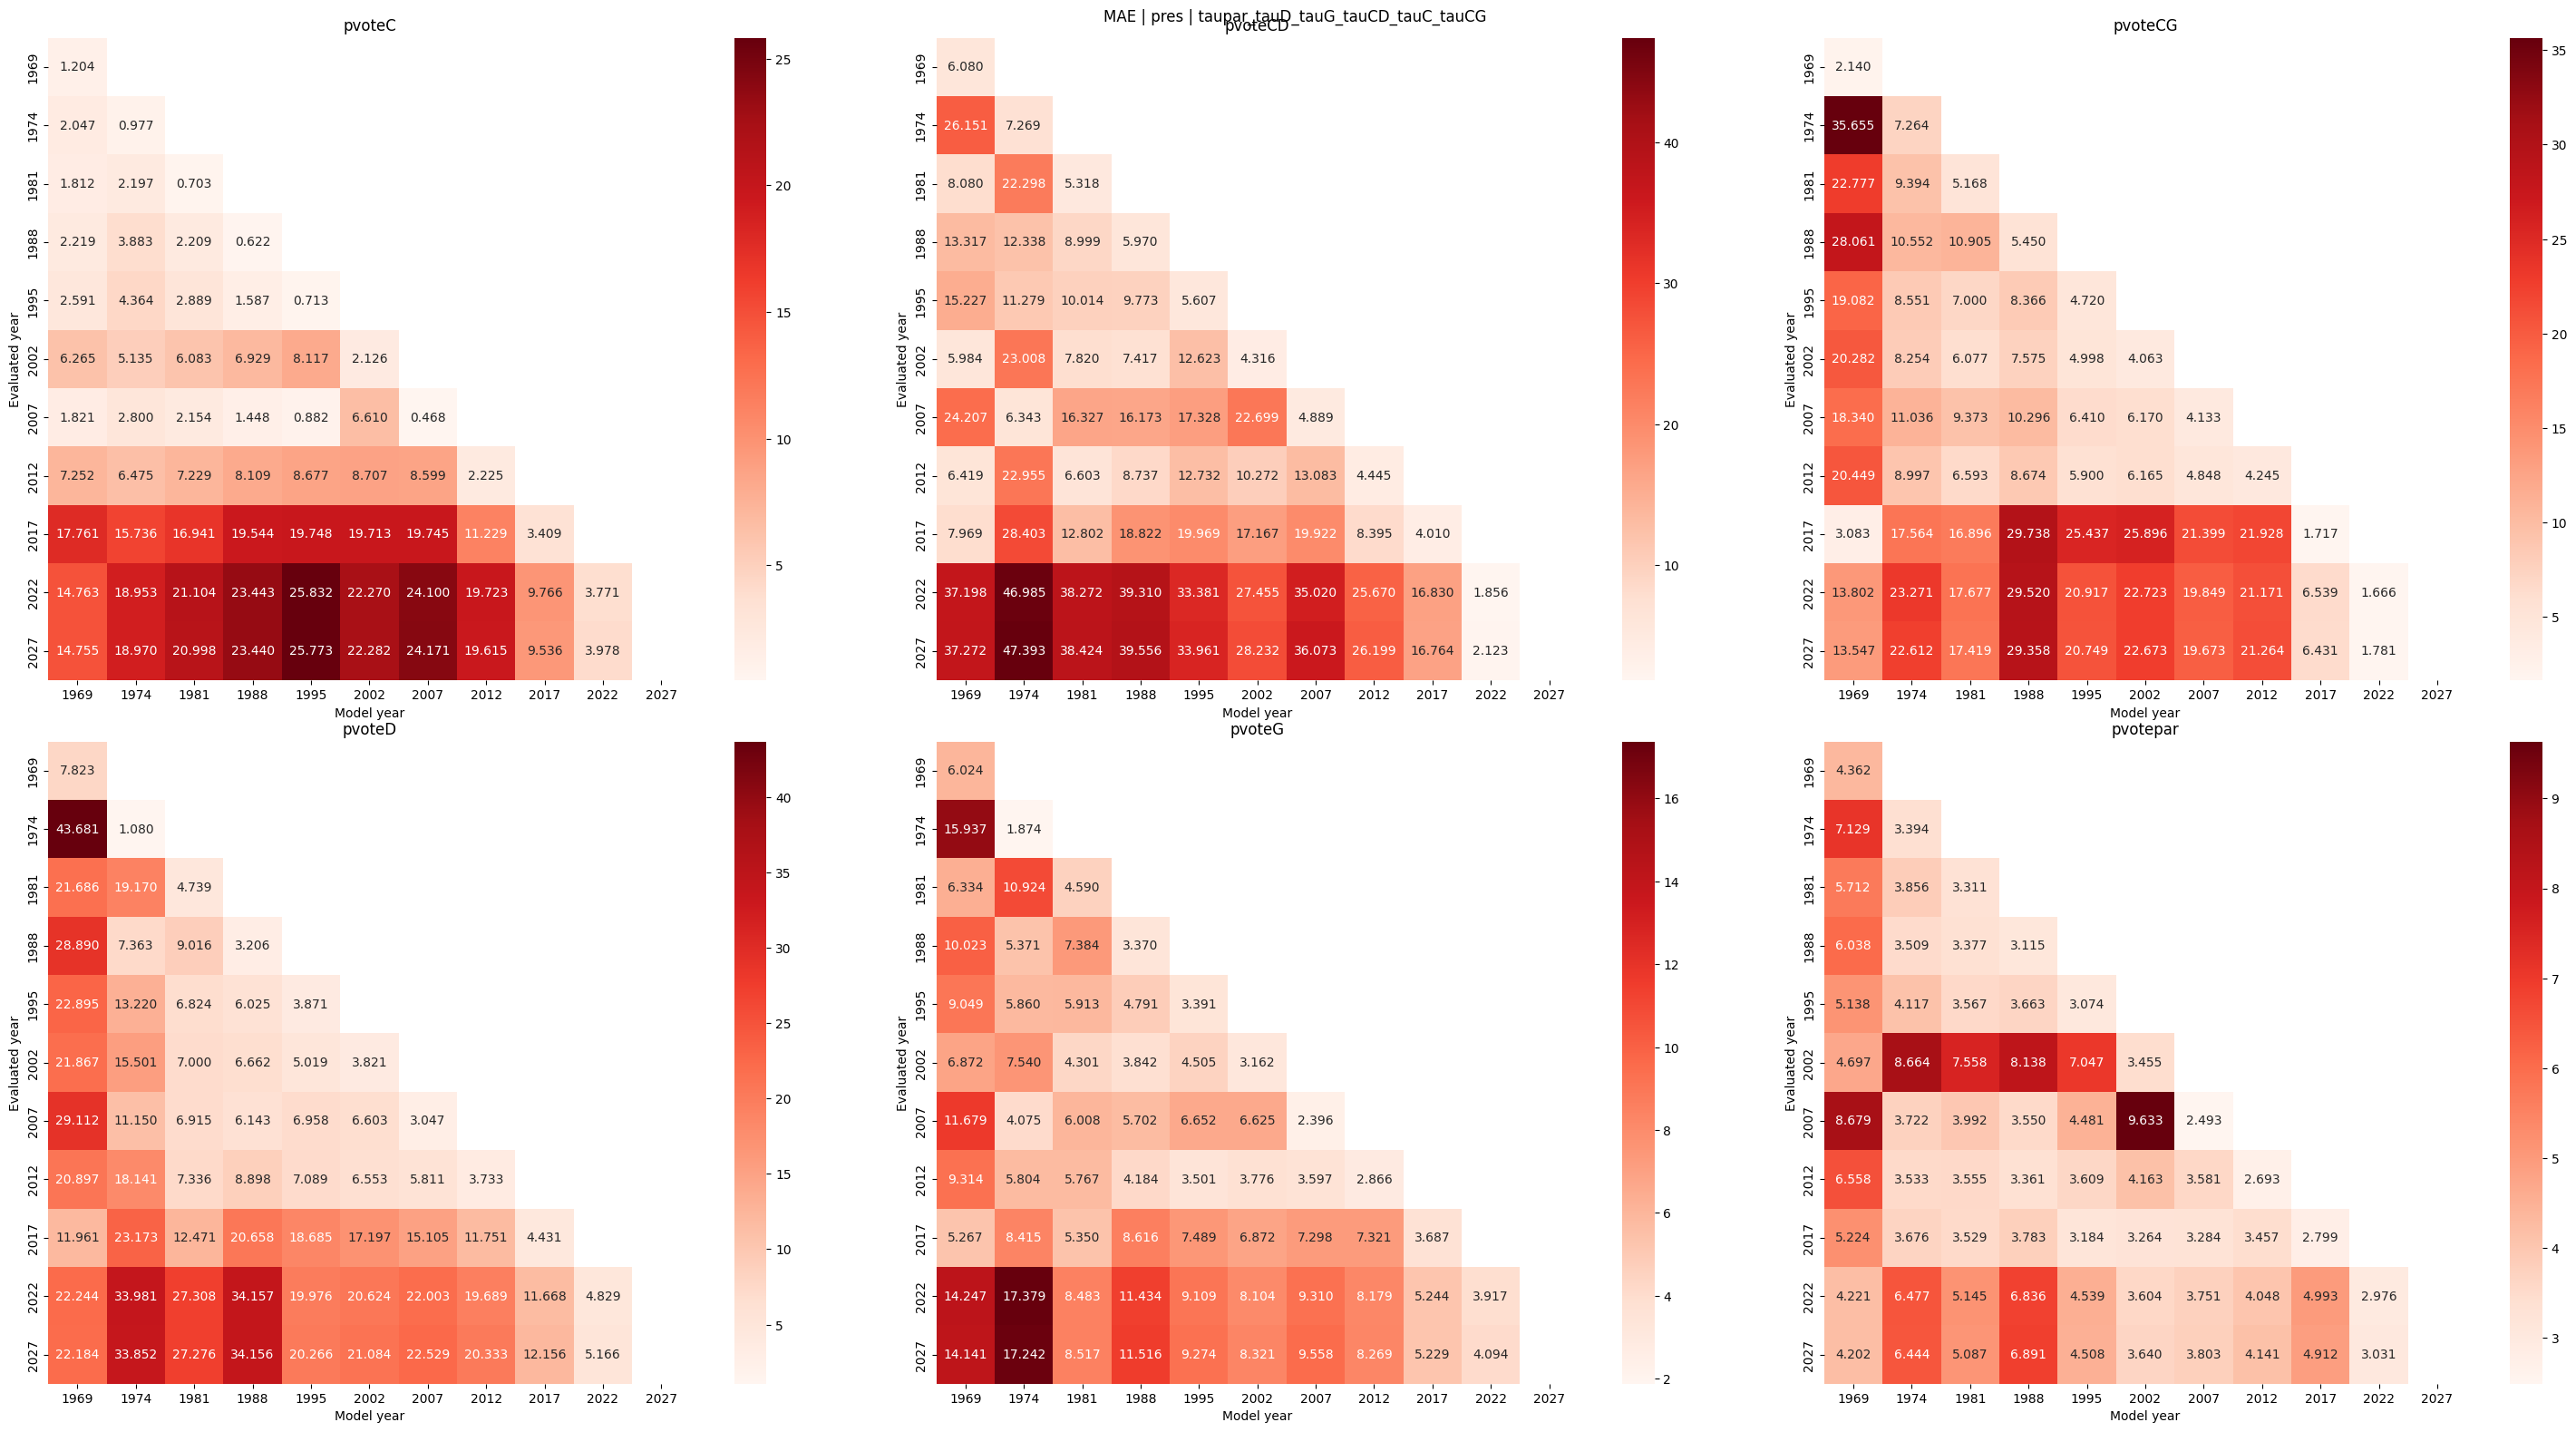

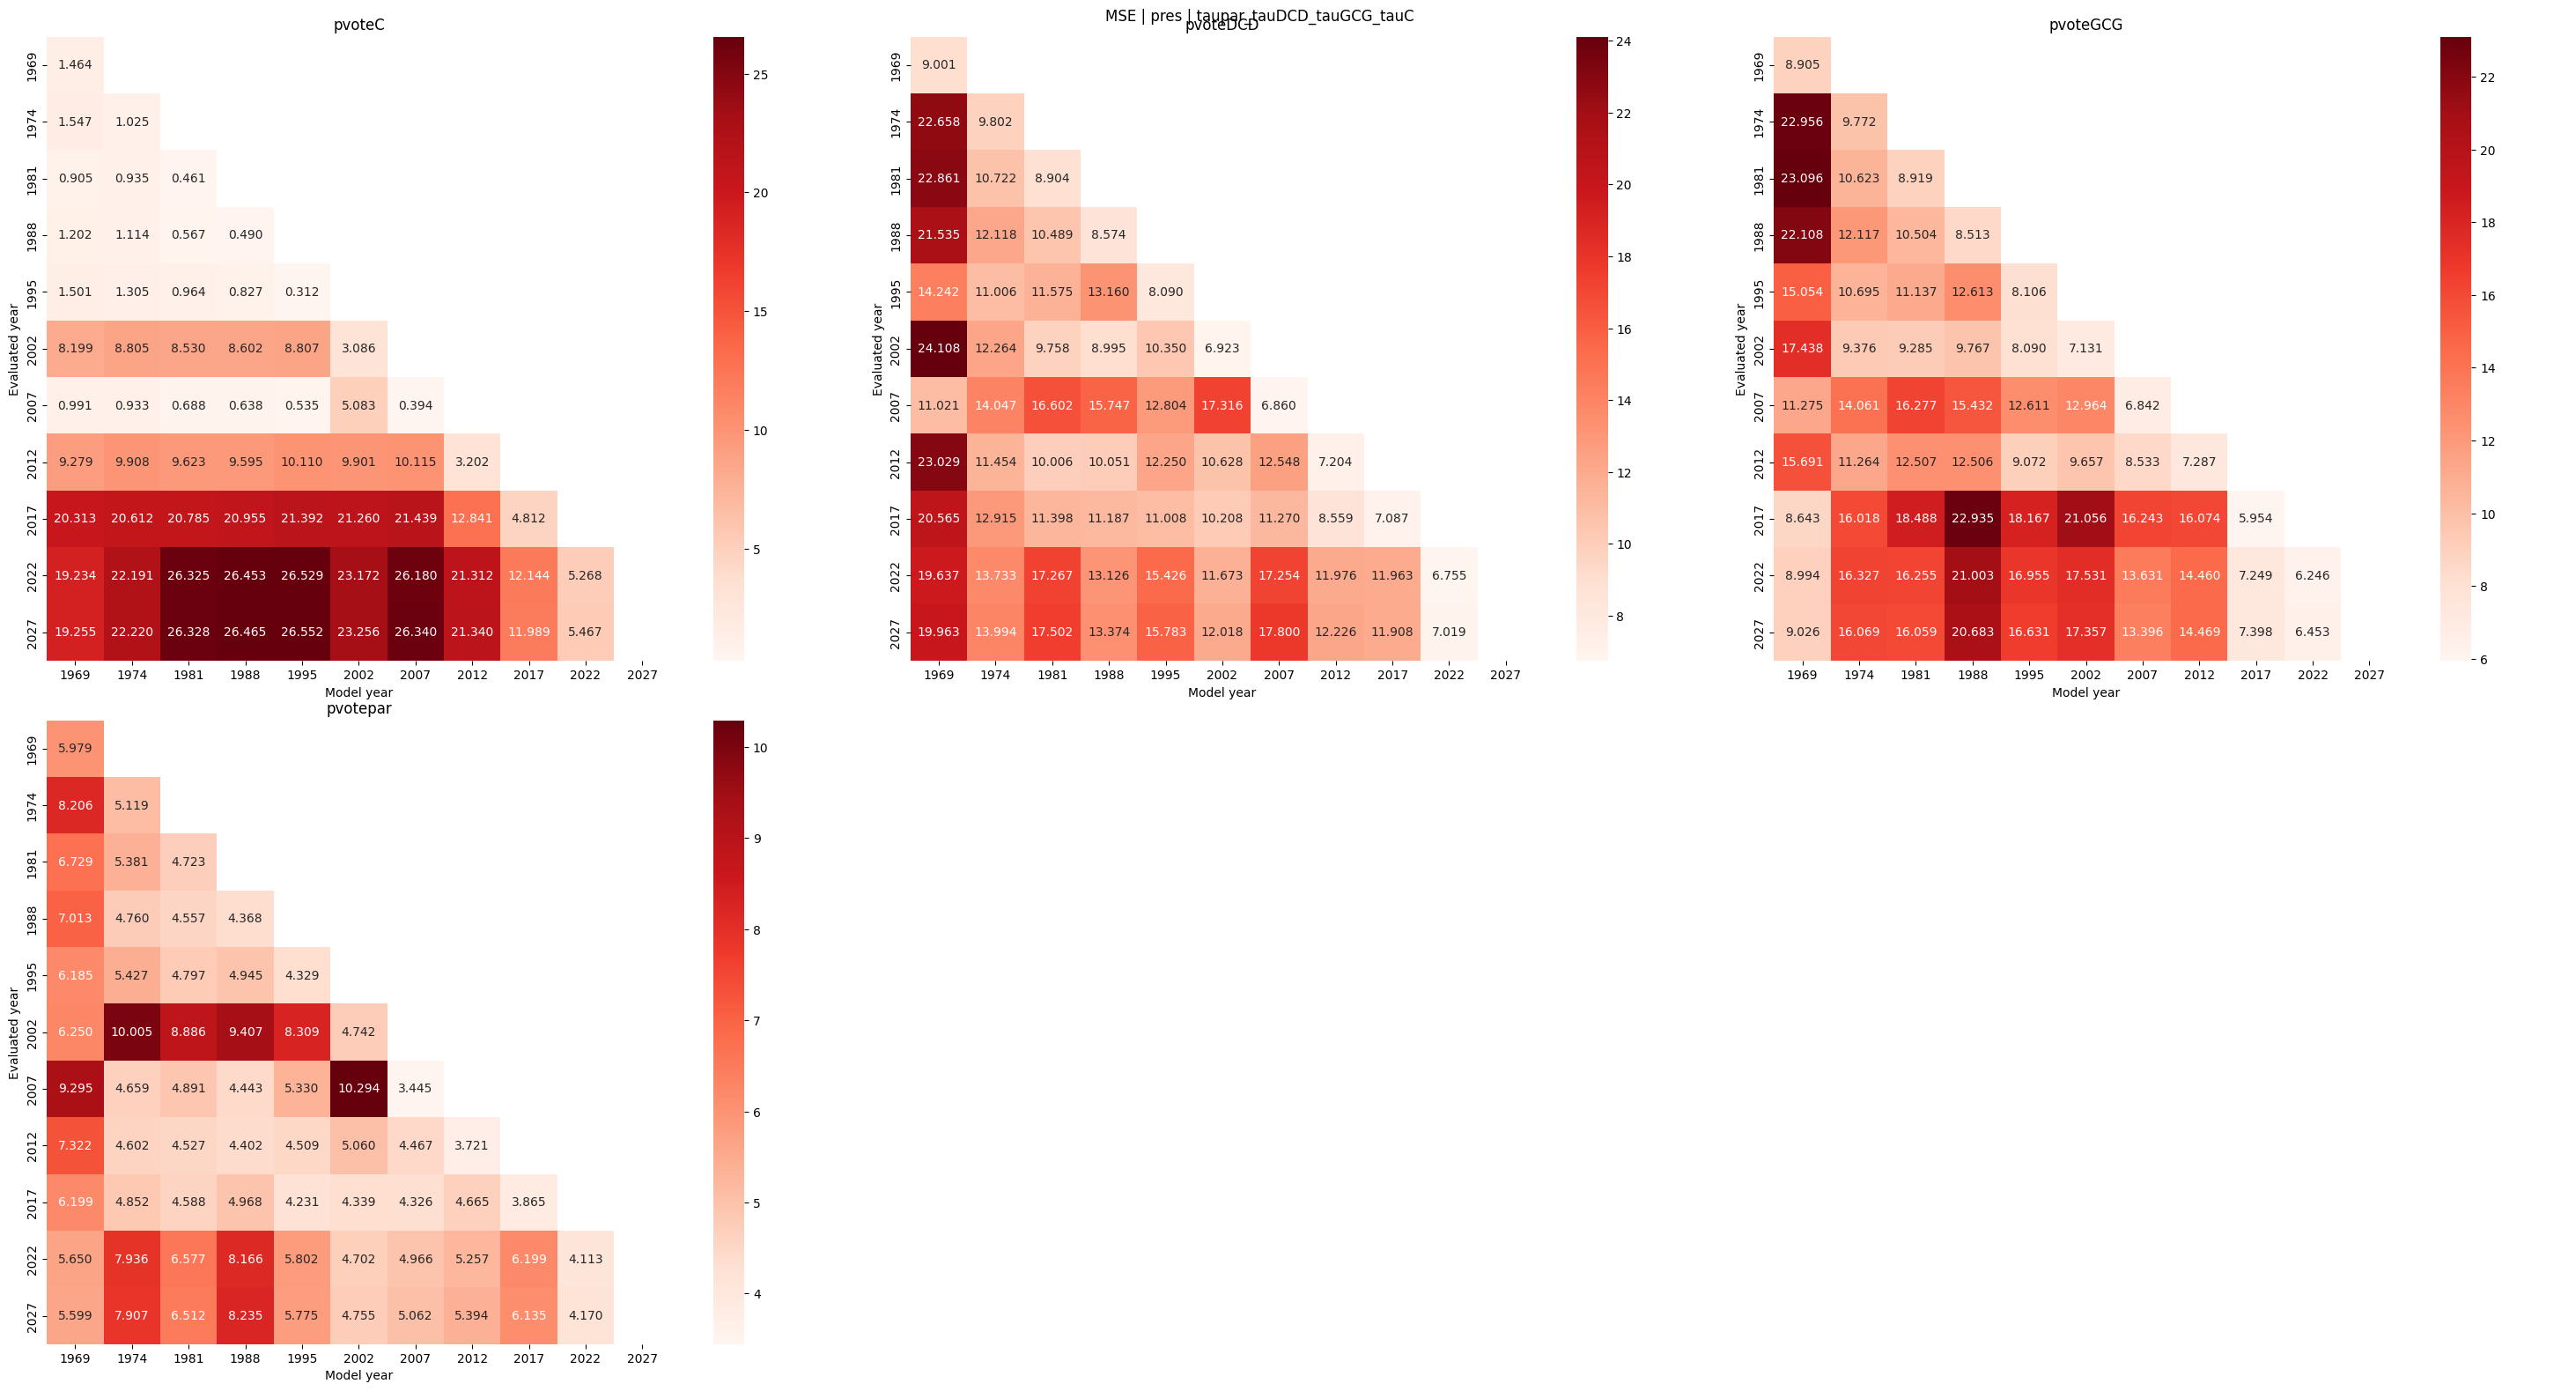

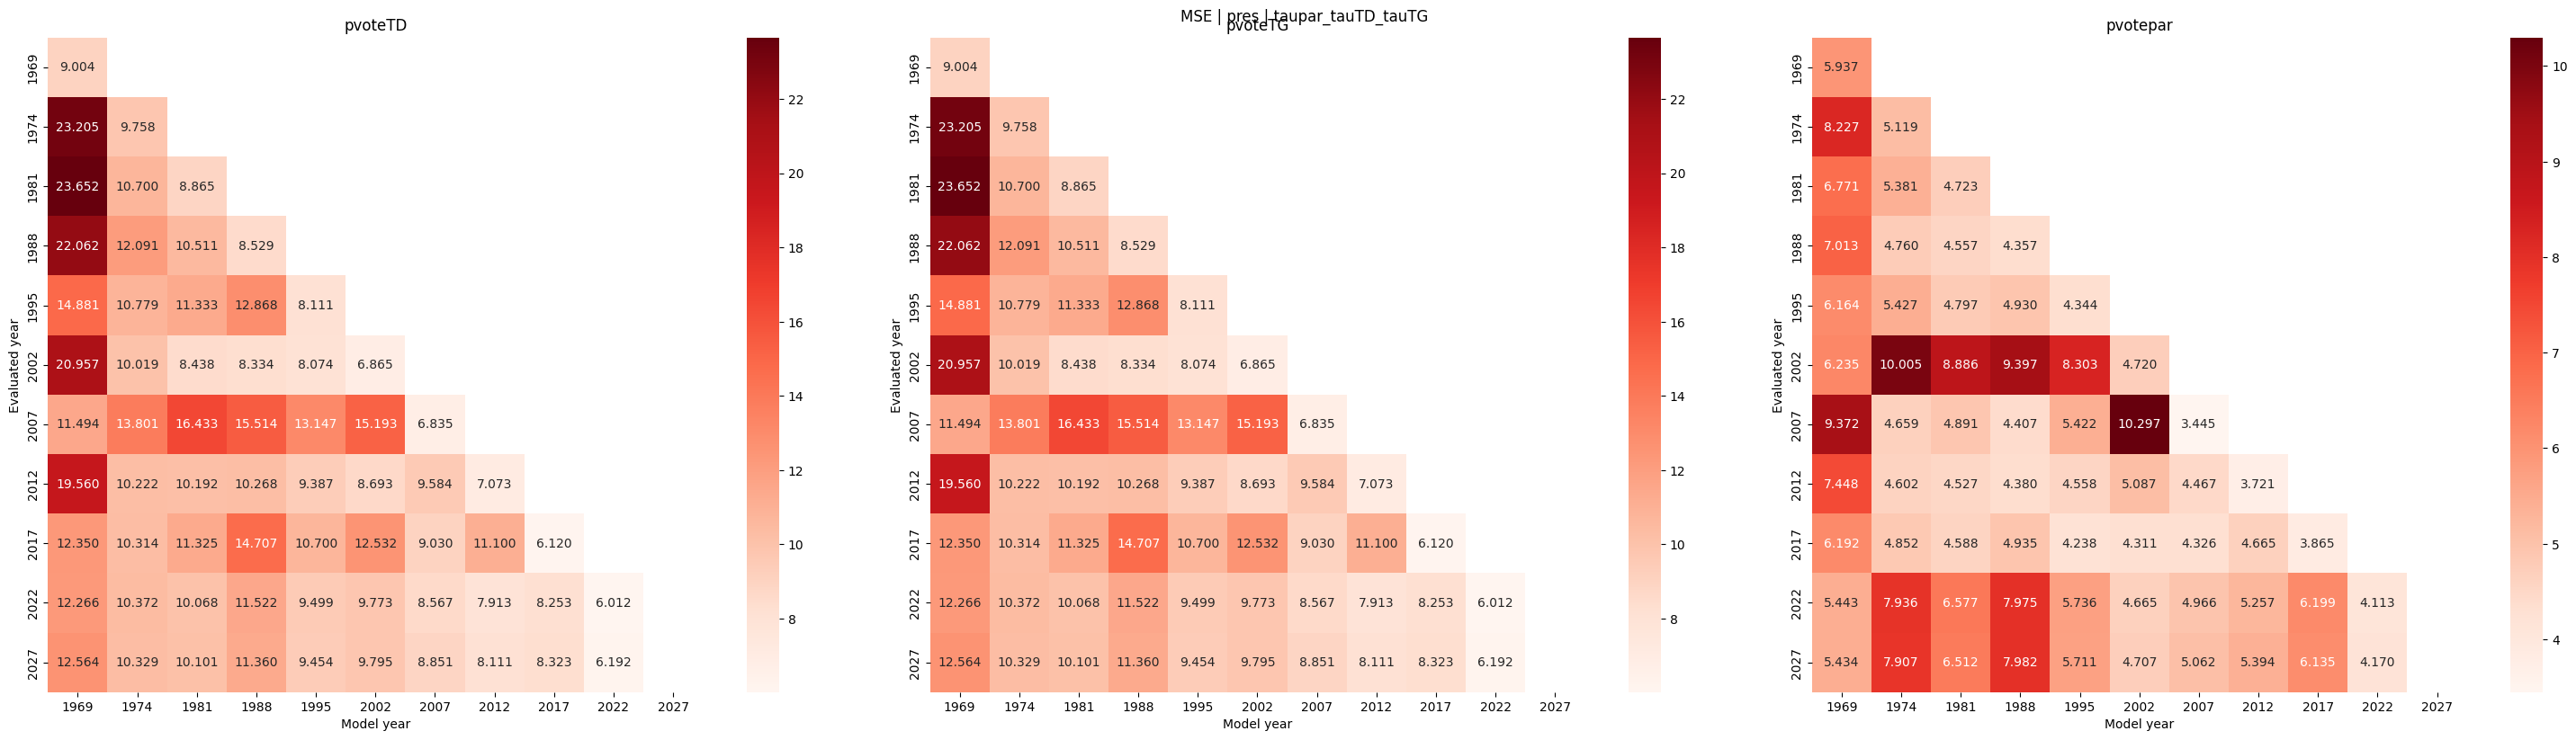

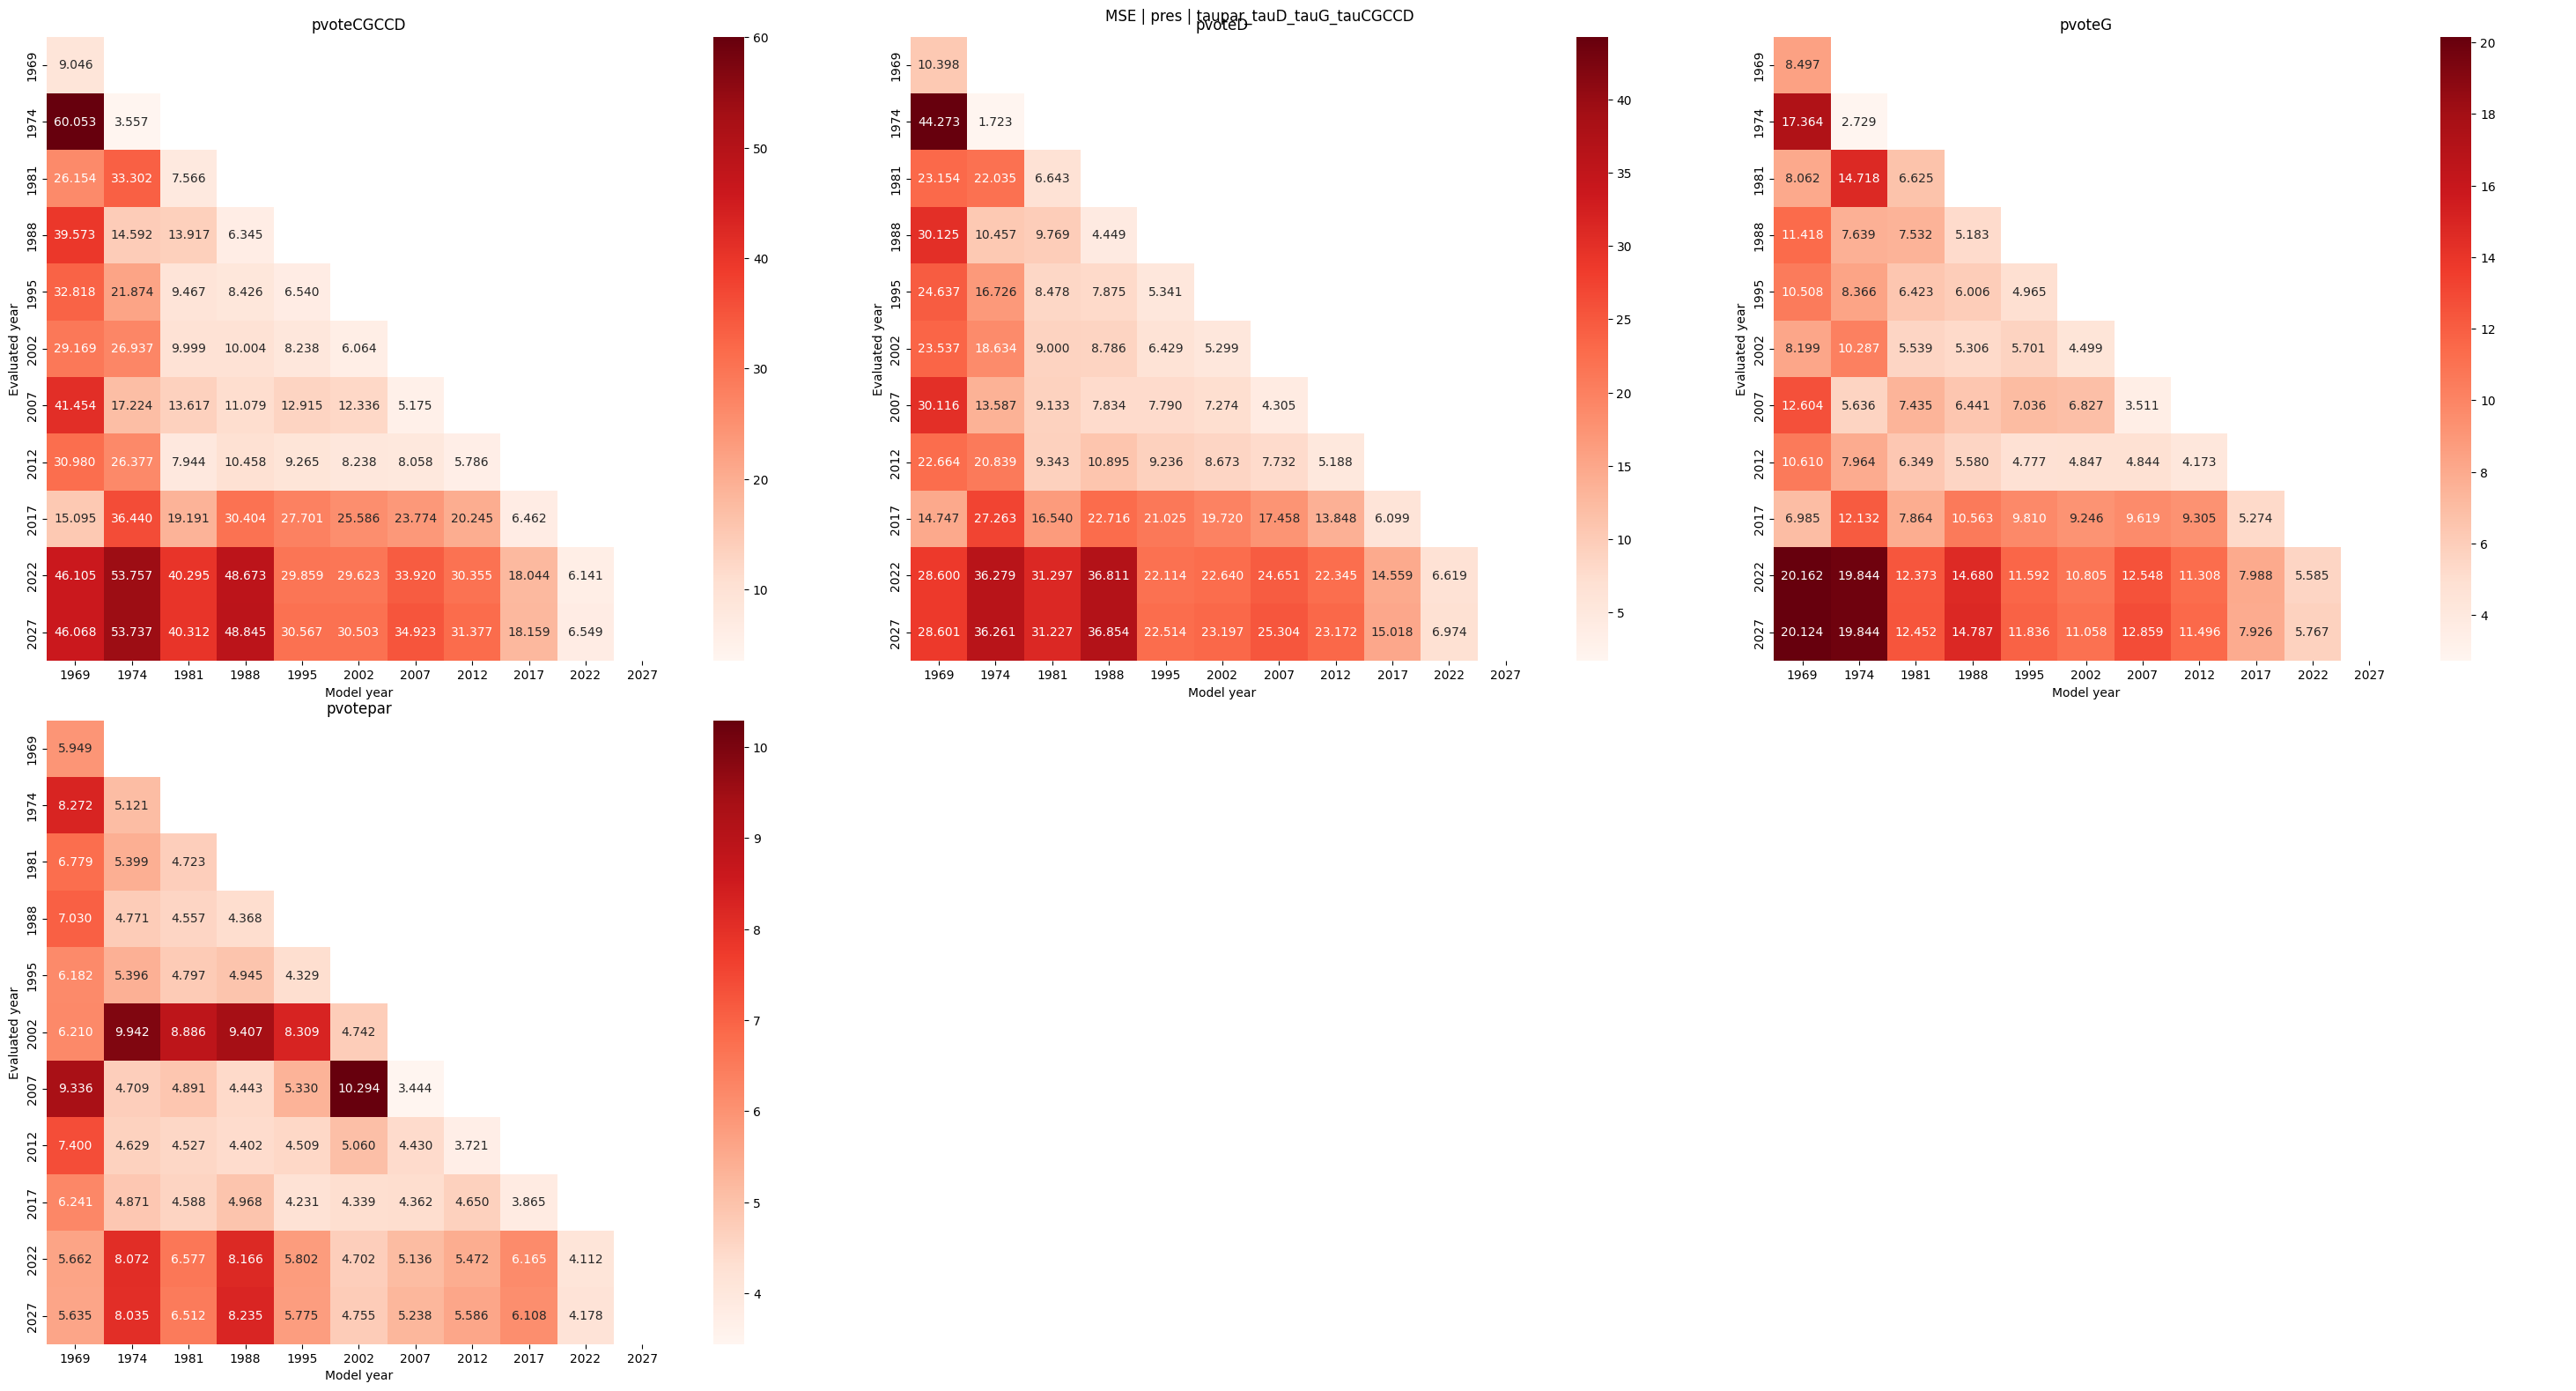

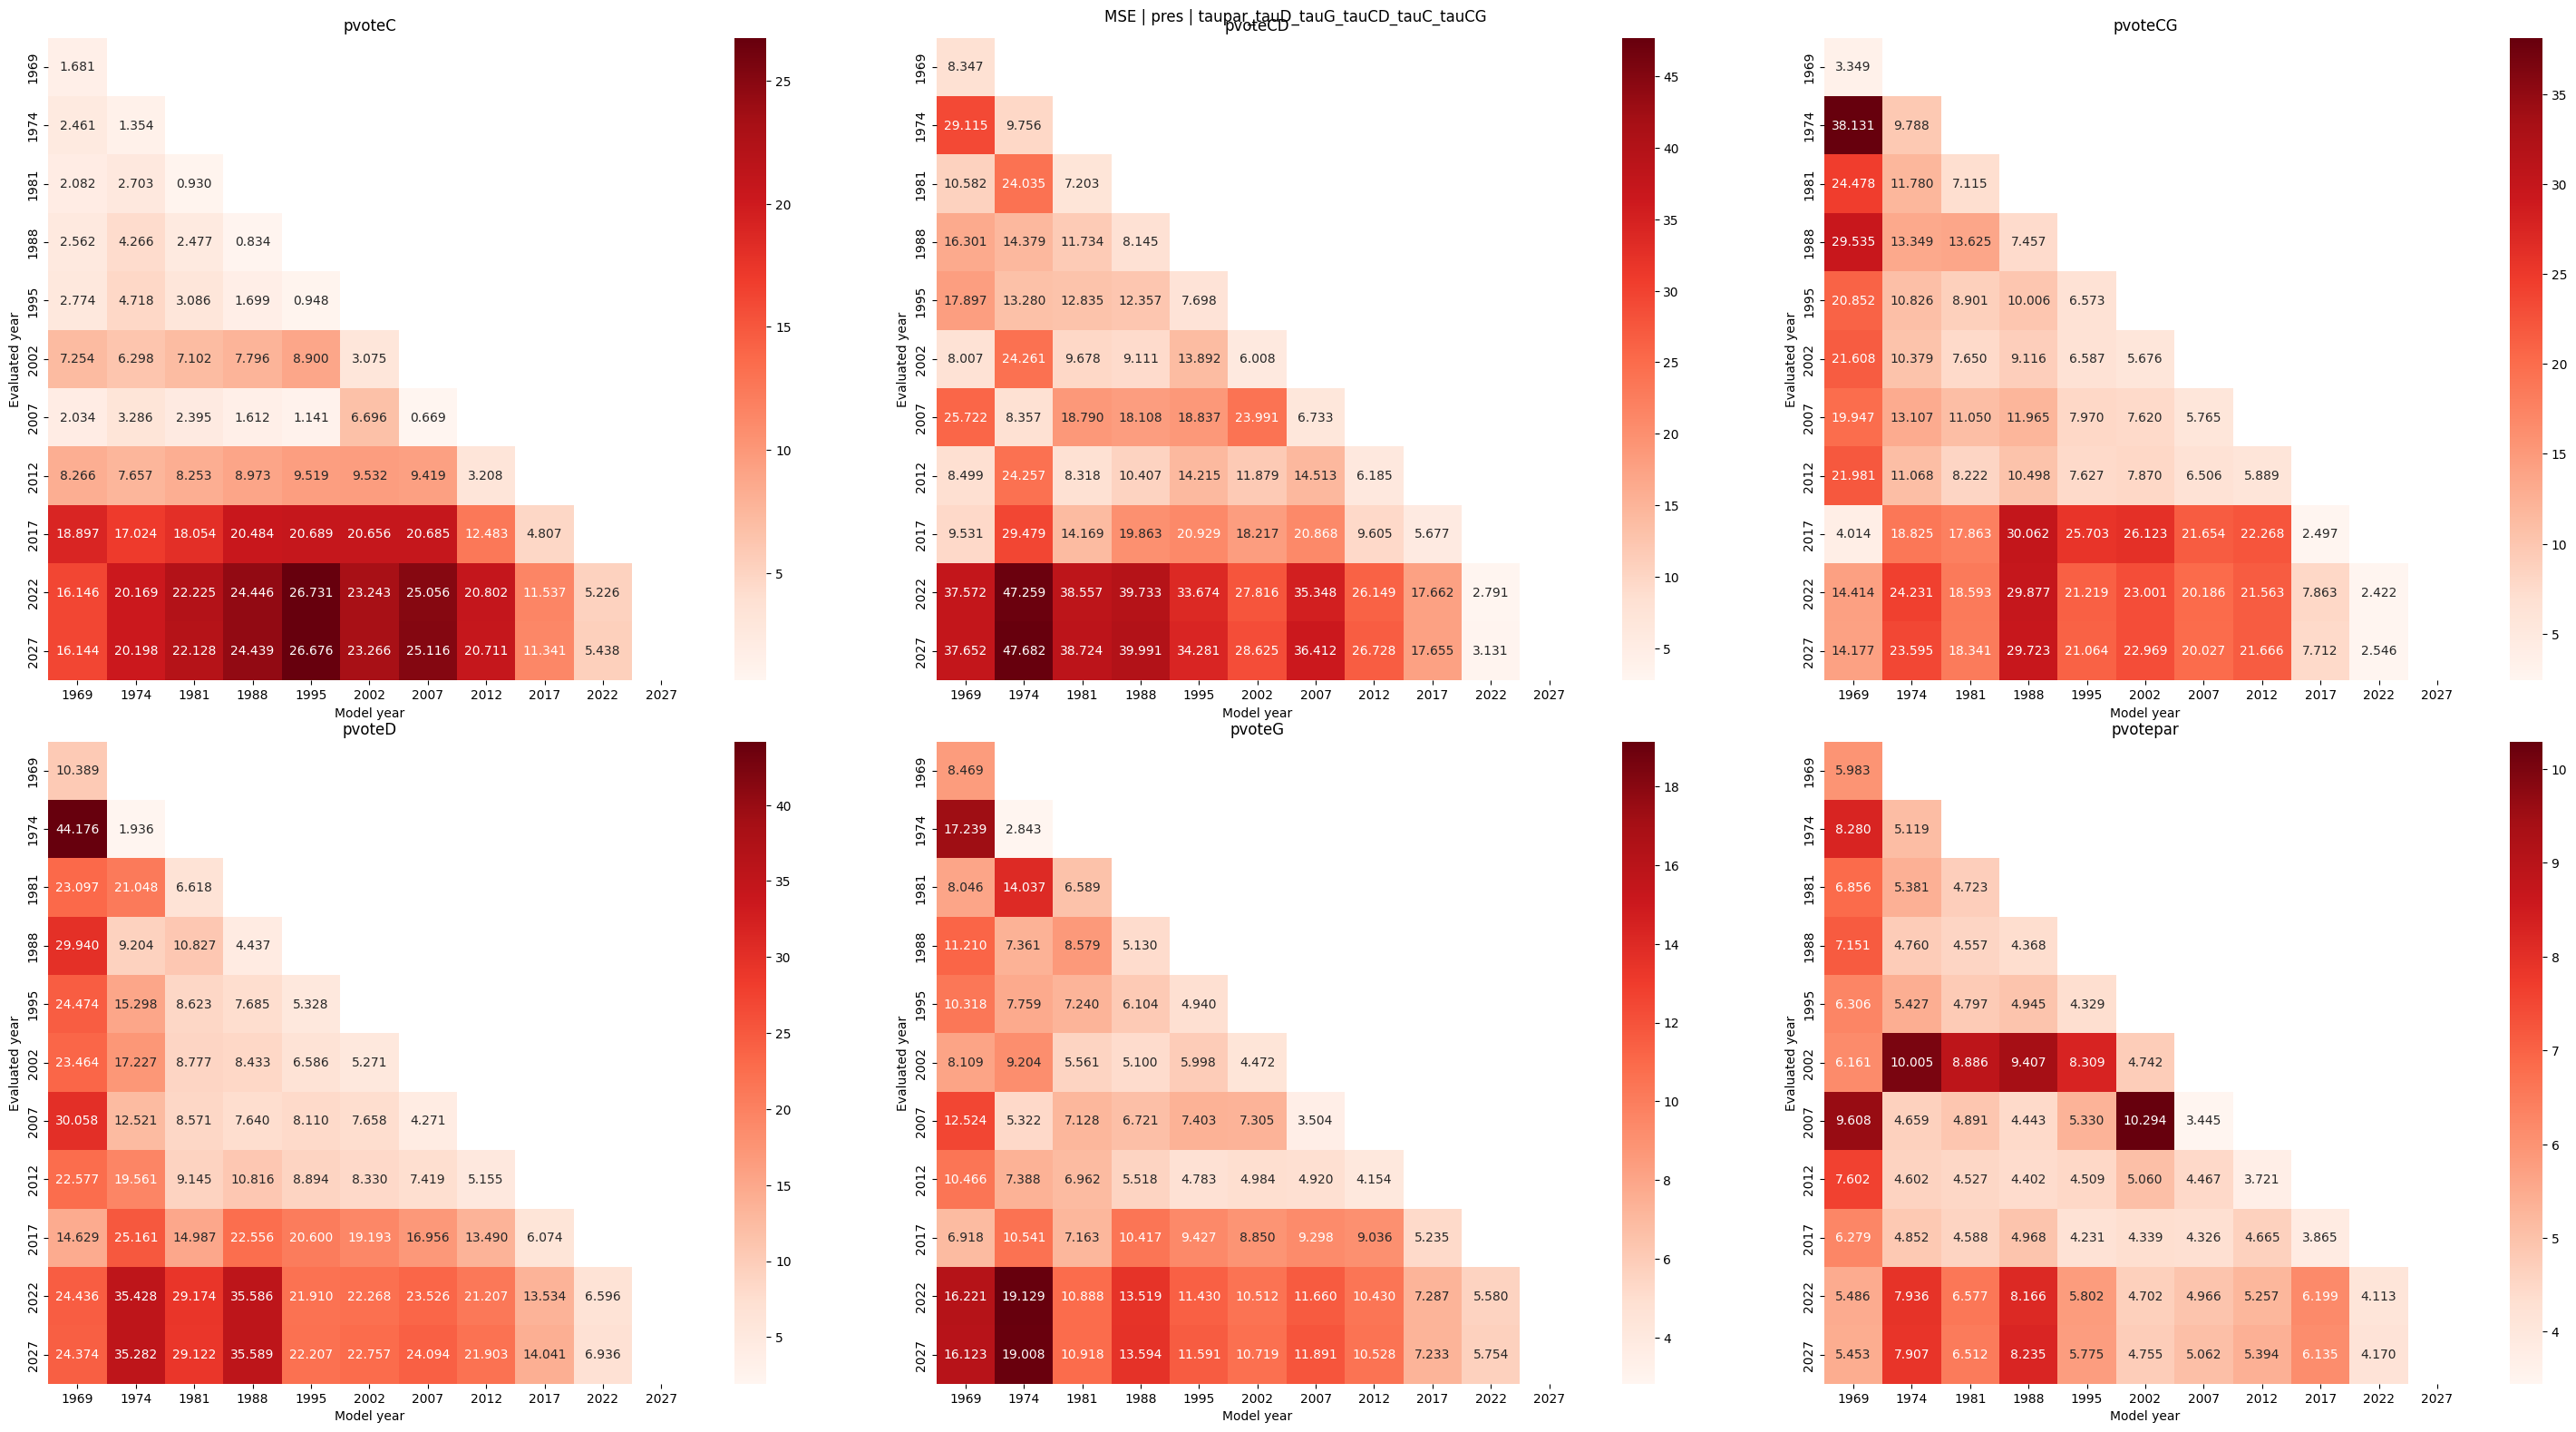

In [100]:

def to_matrix(values: dict, years: list) -> pd.DataFrame:
    # Rows = evaluated year, cols = model year -> filled cells are below the diagonal
    mat = pd.DataFrame(np.nan, index=years, columns=years)
    for (model_year, eval_year), v in values.items():
        mat.loc[eval_year, model_year] = v * 100
    return mat


for metric_name, per_election in metrics.items():
    for election_type, per_trends_key in per_election.items():
        for trends_key, per_trend in per_trends_key.items():
            trends = sorted(per_trend)
            years = sorted({y for d in per_trend.values() for pair in d for y in pair})
            mask = np.triu(np.ones((len(years), len(years)), dtype=bool),k=1)

            n = len(trends)
            ncols = min(3, n)
            nrows = int(np.ceil(n / ncols))
            fig, axes = plt.subplots(
                nrows, ncols, figsize=(10 * ncols, 8 * nrows), squeeze=False
            )

            for ax, trend in zip(axes.flat, trends):
                mat = to_matrix(per_trend[trend], years)
                sns.heatmap(
                    mat, mask=mask, annot=True, fmt=".3f", cmap="Reds",
                    square=True, ax=ax,
                )
                ax.set_title(trend)
                ax.set_xlabel("Model year")
                ax.set_ylabel("Evaluated year")

            for ax in axes.flat[n:]:
                ax.axis("off")

            fig.suptitle(f"{metric_name.upper()} | {election_type} | {trends_key}")
            fig.tight_layout()
            plt.show()